# Assignment 7: Classification Analysis | Pair Assignment

**Goal:** build and compare a **Decision Tree** and a **Naive Bayes** classifier on your
group's dataset, then report what you found. EAch pair will choose one dataset from the following table and do the following.


Hints are provided in the cells marked `# TODO`. If you get stuck on syntax, check the code examples form this week.

> **Replace the loan_sample.cs with your chosen Kaggle dataset** and update the target column.

## Your dataset

| Group dataset | Example classification task | Target column | Kaggle link |
|---|---|---|---|
| SF Crime | Predict crime category, or district | `Category` / `PdDistrict` | https://www.kaggle.com/competitions/sf-crime/data
| NASA Asteroids | Predict if an asteroid is hazardous | `Hazardous` | https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
| Hotel Booking | Predict if a booking is cancelled, or hotel type | `is_canceled` / `hotel` | https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Use a Decision Tree for one task and Naive Bayes for the other (or, for Asteroids, run
both on the same task and compare). Keep notes as you go; you will need them for the report
at the bottom.

## Know your dataset before you start | Each pair will choose one of the following dataset

Read the block for your group's dataset first. It tells you what you are actually
predicting and the specific things to watch for at each step, so you are not surprised
halfway through.

### SF Crime, predicting crime category or district

**What you are figuring out:** can the time and place of an incident predict what kind of
crime it was, or which police district it happened in? You are turning raw incident logs
into useful predictors.

- **Exploration:** this file is huge (about 1 million rows). Take a random sample (say 50,000 rows) so your code runs fast. Check how many distinct crime categories exist.
- **Preprocessing:** the timestamp is not useful as text. Pull `hour`, `day of week`, and `month` out of it into their own numeric columns. If there are too many crime categories, group the rare ones into an "Other" bucket so the model is not splitting on dozens of tiny classes. Keep latitude and longitude; they are strong predictors.
- **Build models:** Decision Tree for one task (for example, category) and Naive Bayes for the other (district).
- **Evaluate:** with many classes, accuracy alone is thin. Look at the confusion matrix to see which categories get mixed up.

### NASA Asteroids, predicting hazardous (yes / no)

**What you are figuring out:** from an asteroid's size and orbital measurements, can you
predict whether NASA flags it as hazardous? This is the cleanest Decision Tree versus
Naive Bayes comparison of the three.

- **Exploration:** check the class balance first. Only about 16% are hazardous, so a model that always guesses "not hazardous" is already about 84% accurate. That is the baseline you must beat, and it is why accuracy alone will mislead you.
- **Preprocessing:** drop columns that carry no signal, such as `id` and `name`. The features are on very different scales (diameter versus orbital period), so apply feature scaling. This matters a lot for Naive Bayes.
- **Build models:** run both a Decision Tree and Naive Bayes on the same task and compare them directly.
- **Evaluate:** because the classes are imbalanced, report precision and recall for the "hazardous" class, not just accuracy. Recall matters most here: a missed hazardous asteroid is the costly error.

### Hotel Booking, predicting cancellation or hotel type

**What you are figuring out:** can booking details predict whether a reservation will be
cancelled, or whether it is a city versus resort hotel? This one is encoding-heavy.

- **Exploration:** check the cancellation rate (the classes may be imbalanced) and scan which columns are text versus numeric.
- **Preprocessing:** many columns are categorical and need encoding (`get_dummies` or `LabelEncoder`). Date columns are not useful raw; pull out useful pieces like the month. Watch for NULLs that are actually meaningful: a missing travel-agent value usually means "no agent," not bad data, so do not blindly drop those rows.
- **Build models:** Decision Tree for one task, Naive Bayes for the other.
- **Evaluate:** if cancellations are the minority class, look at precision and recall for cancellations, not just overall accuracy.

In [1]:
# Prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Ready.")

Ready.


## Step 1 - Data exploration

Load your data and get to know it: how many rows and columns, what the columns mean, and
how balanced the classes are. Class balance matters: if 90% of rows are one class, a model
can look accurate just by guessing that class every time.

In [2]:
import random

n_rows = 878049
keep = set(random.Random(1).sample(range(1, n_rows + 1), 50000))

df = pd.read_csv(
    "data/train.csv.zip",
    skiprows=lambda i: i != 0 and i not in keep
).copy()

print(df.shape)
target = "Category"
df.head()

(50000, 9)


,Dates,Category,Descript,DayOfWeek,PdDistrict,Resolution,Address,X,Y
0,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,PARK,NONE,100 Block of BRODERICK ST,-122.438738,37.771541
1,2015-05-13 19:30:00,SUSPICIOUS OCC,INVESTIGATIVE DETENTION,Wednesday,SOUTHERN,NONE,OTIS ST / GOUGH ST,-122.420347,37.771769
2,2015-05-13 19:19:00,NON-CRIMINAL,"AIDED CASE, MENTAL DISTURBED",Wednesday,SOUTHERN,NONE,0 Block of MARKET ST,-122.395098,37.794059
3,2015-05-13 19:00:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,NORTHERN,NONE,2000 Block of SUTTER ST,-122.434121,37.786033
4,2015-05-13 18:45:00,OTHER OFFENSES,"DRIVERS LICENSE, SUSPENDED OR REVOKED",Wednesday,MISSION,"ARREST, BOOKED",17TH ST / TREAT AV,-122.413592,37.763822


In [3]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[target].value_counts()
# Also try df.describe() for the numeric columns.
print(df.shape)
print()
df.info()
print()
print("Distinct categories:", df[target].nunique())
print(df[target].value_counts())
print()
print(df["PdDistrict"].value_counts())
df.describe()


(50000, 9)

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Dates       50000 non-null  str    
 1   Category    50000 non-null  str    
 2   Descript    50000 non-null  str    
 3   DayOfWeek   50000 non-null  str    
 4   PdDistrict  50000 non-null  str    
 5   Resolution  50000 non-null  str    
 6   Address     50000 non-null  str    
 7   X           50000 non-null  float64
 8   Y           50000 non-null  float64
dtypes: float64(2), str(7)
memory usage: 3.4 MB

Distinct categories: 37
Category
LARCENY/THEFT                  9894
OTHER OFFENSES                 7121
NON-CRIMINAL                   5184
ASSAULT                        4390
VEHICLE THEFT                  3026
DRUG/NARCOTIC                  3025
VANDALISM                      2669
WARRANTS                       2395
BURGLARY                       2067
SUSPICIOUS OCC                 181

,X,Y
count,50000.000000,50000.000000
mean,-122.422735,37.770194
std,0.029480,0.405308
min,-122.513642,37.707922
25%,-122.433013,37.752418
50%,-122.416459,37.775421
75%,-122.406959,37.784348
max,-120.500000,90.000000


## Step 2 - Preprocessing

Get the data ready for the models. You will typically need to:

- Drop columns that are just identifiers or are not useful (e.g. an ID column).
- Handle missing values (fill numeric columns with the median, text columns with the mode).
- Encode categorical (text) columns into numbers with `pd.get_dummies(...)` or `LabelEncoder`.
- Separate the target `y` from the features `X`, then split into train and test sets.

In [4]:
# TODO: drop unhelpful columns and handle missing values
# Hint: start from a copy -> data = df.drop(columns=["applicant_id"]).copy()
# Hint for missing values, loop over columns:
#   if pd.api.types.is_numeric_dtype(data[col]): fill with data[col].median()
#   else: fill with data[col].mode()[0]
data = df.drop(columns=["Descript", "Resolution", "Address"]).copy()

data["Dates"] = pd.to_datetime(data["Dates"])
data["hour"] = data["Dates"].dt.hour
data["day_of_week"] = data["Dates"].dt.dayofweek
data["month"] = data["Dates"].dt.month
data = data.drop(columns=["Dates", "DayOfWeek"])

# X= Longitude, Y = Latitude. A few rows have bad cordinates, so we are removing them
data = data[data["Y"] < 90]

#Group rare crime categories into the "Other" csategory and just keep top 10
top_cats = data["Category"].value_counts().head(10).index
data["Category"] = data["Category"].where(data["Category"].isin(top_cats), "Other")


In [5]:
# TODO: build X (features) and y (target), then encode the categorical columns
# Hint: y = data[target]
# Hint: X = pd.get_dummies(data.drop(columns=[target]), drop_first=True)

features = ["hour", "day_of_week", "month", "X", "Y"]
X = data[features]


In [6]:
# TODO: split into training and test sets
# Hint: X_train, X_test, y_train, y_test = train_test_split(
#           X, y, test_size=0.25, random_state=1, stratify=y)

#Task 1 : Category (Decision Tree)
y_cat = data["Category"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_cat, test_size=0.25, random_state=1, stratify=y_cat)

#Task 2 : PdDistrict (Naive Bayes)
y_dist = data["PdDistrict"]
Xp_train, Xp_test, yd_train, yd_test = train_test_split(
    X, y_dist, test_size=0.25, random_state=1, stratify=y_dist)


## Step 3 - Build the models

Each classifier is only a few lines: create it, then call `.fit(X_train, y_train)`.

In [7]:
# TODO: train a Decision Tree
# Hint: dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
#       dtree.fit(X_train, y_train)

dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(Xc_train, yc_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

In [8]:
# TODO: train a Naive Bayes classifier
# Hint: nb_model = GaussianNB()
#       nb_model.fit(X_train, y_train)

nb_model = GaussianNB()
nb_model.fit(Xp_train, yd_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](10,)","[3804.,3710.,3366.,...,6671.,2816.,3505.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](10,)","[0.1 ,0.1 ,0.09,...,0.18,0.08,0.09]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U10](10,)","['BAYVIEW','CENTRAL','INGLESIDE',...,'SOUTHERN','TARAVAL','TENDERLOIN']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,4.339e-08
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['hour','day_of_week','month','X','Y']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](10, 5)","[[ 13.8 , 3.04, 6.4 ,-122.39, 37.74], [ 13.05, 3.14, 6.49,-122.41, 37.8 ], [ 13.76, 3.01, 6.38,-122.43, 37.73], ..., [ 13.51, 3.02, 6.51,-122.41, 37.78], [ 13.42, 2.96, 6.48,-122.48, 37.74], [ 13.44, 2.92, 6.43,-122.41, 37.78]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](10, 5)","[[39.74, 3.93,11.76, 0. , 0. ], [47.44, 3.9 ,11.87, 0. , 0. ], [42.7 , 3.84,11.72, 0. , 0. ], ..., [41.66, 3.9 ,11.63, 0. , 0. ], [41.21, 3.84,12.05, 0. , 0. ], [38.52, 3.81,11.68, 0. , 0. ]]"


## Step 4 - Evaluate and compare

For **each** model, predict on the test set and report:

- accuracy (`accuracy_score`)
- the confusion matrix (`ConfusionMatrixDisplay.from_predictions`)
- precision, recall, and F1 (`classification_report`)

Then compare: which model is more accurate, and what do the precision and recall for the
class you care about tell you?

0.2428


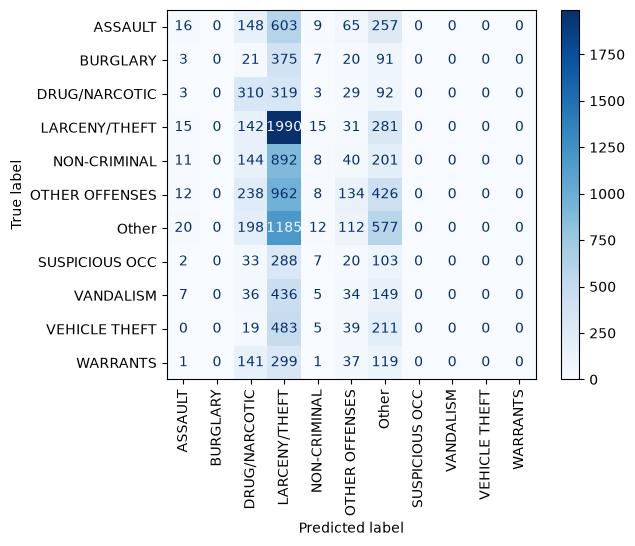

                precision    recall  f1-score   support

       ASSAULT       0.18      0.01      0.03      1098
      BURGLARY       0.00      0.00      0.00       517
 DRUG/NARCOTIC       0.22      0.41      0.28       756
 LARCENY/THEFT       0.25      0.80      0.39      2474
  NON-CRIMINAL       0.10      0.01      0.01      1296
OTHER OFFENSES       0.24      0.08      0.11      1780
         Other       0.23      0.27      0.25      2104
SUSPICIOUS OCC       0.00      0.00      0.00       453
     VANDALISM       0.00      0.00      0.00       667
 VEHICLE THEFT       0.00      0.00      0.00       757
      WARRANTS       0.00      0.00      0.00       598

      accuracy                           0.24     12500
     macro avg       0.11      0.14      0.10     12500
  weighted avg       0.16      0.24      0.16     12500



In [9]:
# TODO: evaluate the Decision Tree
# Hint: dt_pred = dtree.predict(X_test)
#       print(accuracy_score(y_test, dt_pred))
#       ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues"); plt.show()
#       print(classification_report(y_test, dt_pred))

dt_pred = dtree.predict(Xc_test)
print(accuracy_score(yc_test, dt_pred))
ConfusionMatrixDisplay.from_predictions(yc_test, dt_pred, cmap="Blues", xticks_rotation=90)
plt.show()
print(classification_report(yc_test, dt_pred, zero_division=0))


0.86152


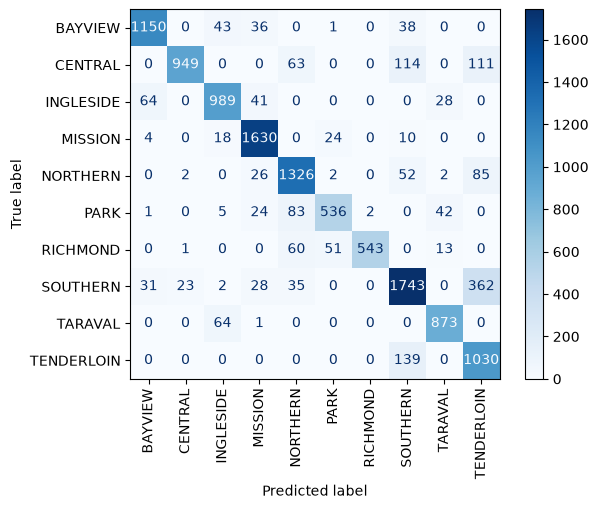

              precision    recall  f1-score   support

     BAYVIEW       0.92      0.91      0.91      1268
     CENTRAL       0.97      0.77      0.86      1237
   INGLESIDE       0.88      0.88      0.88      1122
     MISSION       0.91      0.97      0.94      1686
    NORTHERN       0.85      0.89      0.87      1495
        PARK       0.87      0.77      0.82       693
    RICHMOND       1.00      0.81      0.90       668
    SOUTHERN       0.83      0.78      0.81      2224
     TARAVAL       0.91      0.93      0.92       938
  TENDERLOIN       0.65      0.88      0.75      1169

    accuracy                           0.86     12500
   macro avg       0.88      0.86      0.86     12500
weighted avg       0.87      0.86      0.86     12500



In [10]:
# TODO: evaluate the Naive Bayes model (same steps as above)

nb_pred = nb_model.predict(Xp_test)
print(accuracy_score(yd_test, nb_pred))
ConfusionMatrixDisplay.from_predictions(yd_test, nb_pred, cmap="Blues", xticks_rotation=90)
plt.show()
print(classification_report(yd_test, nb_pred, zero_division=0))


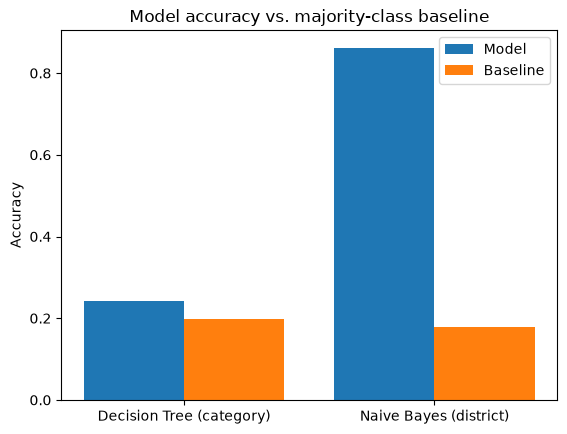

In [11]:
# TODO: compare the two models' accuracy against a baseline
# Hint: baseline = y_test.value_counts(normalize=True).max()
# A simple bar chart makes the comparison clear.

dt_baseline = yc_test.value_counts(normalize=True).max()
nb_baseline = yd_test.value_counts(normalize=True).max()

labels = ["Decision Tree (category)", "Naive Bayes (district)"]
model_acc = [accuracy_score(yc_test, dt_pred), accuracy_score(yd_test, nb_pred)]
baseline_acc = [dt_baseline, nb_baseline]

x = range(len(labels))
plt.bar([i - 0.2 for i in x], model_acc, width=0.4, label="Model")
plt.bar([i + 0.2 for i in x], baseline_acc, width=0.4, label="Baseline")
plt.xticks(list(x), labels)
plt.ylabel("Accuracy")
plt.title("Model accuracy vs. majority-class baseline")
plt.legend()
plt.show()

## Step 5 - Findings

Write your answers here as you work.

1. **Preprocessing / data reduction** - what did you have to clean, drop, encode, or sample, and why?

   Keon - The full file has around 878,049 rows, so i took a random sample of just 50,000 (random_state=1) so that the code can run quciker and more efficiently. I dropped Descript and Resolution because they basically give away the asnwer (e.g., "Burglary, forcible Entry" basically is the category), also Address because its free text that X and Y already cover. The Dates column isn;t usable as text, so i pulled out hour, day of week, and month as numeric columns, then dropped Dates and DayOfWeek. The describe() function output showed a few rows with junk coordinates (Y = 90), so I removed those. There were 37 crime categories, so I kept the top 10 and grouped the rest into "Other" so the tree isn;t splitting on dozens of tiny classes. There were no missing values, and since the feautures were also numeric, no encoding was actually needed. I split the data into a 75/25 split with stratification so class proportions stay the same in train and test.

2. **Data used** - which features did you select as predictors, and why those?

   Keon - I Used hour, day_of_week, month, X (longitude), and Y (Latitude). Time can affect what kind of crime happens (for example more theft during the day, and more assault late at night,) and Location is our strongest predictor since it directly relates to both crime type and which district the incident or crime falls in. I left PdDistrict out of the feautures because it's the target for the Naive Bayes task and is basically a stand-in for location in the category task.

3. **Findings** - what did the analysis reveal about the data itself (patterns, surprises)?

   Jaleeya - The overall dataset has 37 crime categories, so I grouped everything outside of the top 10 categories into an "Other" category. I also took out the rows that had invalid coordinates. Using location was a good way to predict the district, but it was much harder to predict the crime category from time and place alone. The Decision Tree mostly guessed LARCENY/THEFT and never correctly predicted some categories, like BURGLARY, VANDALISM, VEHICLE THEFT and WARRANTS, which surprised me. For the districts, TENDERLOIN had the lowest precision (0.65), meaning incidents from other districts were often labeled as Tenderloin.



4. **Decision Tree vs Naive Bayes** - which performed better on your task, and what are the
   strengths and shortcomings of each one here?

   Jaleeya - Naive Bayes performed much better, at 86% accuracy on district, whereas the Decision Tree was only 24% accurate on category. Since they predict different things, I compared each one to its own baseline. The Decision Tree was only a little above its baseline of about 20%, while Naive Bayes was far above its baseline of about 18%. The Decision Tree is easier to understand than Naive Bayes, but it mostly predicts the biggest categories and mixes up the smaller ones, which causes it to be less accurate. Naive Bayes works quickly and does well with location because latitude and longitude separate the districts clearly. Its shortcoming is that it assumes the features are independent and bell-shaped, which doesn't really fit hour, day of week and month.


5. **Challenges** - What was difficult, and how did you handle it?

   Keon - My first problem was that pandas coudln't find the data file because it was saved as train.csv.zip instead of train.csv, so I changed the path. I also got a KeyError on 'Y' because i dropped the X and Y columns early, before actually using them to filter out the bad coordinates, so I kept them in the dataset. Another challenge was that the two models predict different things (Category vs District to be exact), so they can't be compared directly. I compared each one to its own majority class baseline instead.

   Jaleeya -When I was running my cells, the notebook kernel crashed, so I had to restart it and rerun every cell in order, since the variables were lost, which took up a lot of extra time.

## Submission checklist

- This notebook (renamed `Last_First_Assignment7.ipynb`), with all cells run and output showing
- Link to your GitHub repository

https://github.com/RealCodingGeeker/Assignment-7